In [ ]:
# --- data paths (see README: data layout) ---
import os
from pathlib import Path

# Root of the data store. Override with the DATA_ROOT environment variable.
DATA_ROOT = os.environ.get(
    "DATA_ROOT",
    "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/AI-IFS-attributioncomparison/pnw2021",
)
# Root of this git repository (found by walking up from the working directory).
REPO = str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts").is_dir()))


In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from matplotlib.animation import FuncAnimation
from matplotlib import axes

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from ipywidgets import interact, SelectionSlider, IntSlider


In [13]:
def maybe_to_celsius(da):
    if float(da.mean()) > 100:
        return da - 273.15
    return da

def standardize(ds):
    rename = {}
    if "lat" in ds.coords:
        rename["lat"] = "latitude"
    if "lon" in ds.coords:
        rename["lon"] = "longitude"
    if "sample" in ds.dims:
        rename["sample"] = "number"
    if rename:
        ds = ds.rename(rename)
    return ds

def anchor_time(ds, init_time):
    return ds.assign_coords(time=pd.to_datetime(init_time) + ds["time"])


def combine_seed_ensembles(seed_paths):
    """
    Combine multiple GenCast seed files into a single ensemble
    along the 'sample' dimension.
    """
    datasets = []
    offset = 0

    for path in seed_paths:
        ds = xr.open_zarr(path)

        # remove trivial batch dimension
        if "batch" in ds.dims and ds.sizes["batch"] == 1:
            ds = ds.squeeze("batch")

        nmem = ds.sizes["sample"]

        # relabel members to avoid duplicates
        ds = ds.assign_coords(
            sample=np.arange(offset, offset + nmem)
        )

        datasets.append(ds)
        offset += nmem

    return xr.concat(datasets, dim="sample").sortby("sample")

def prepare_gencast_from_seeds(seed_paths, init_time):
    gencast = combine_seed_ensembles(seed_paths)

    if "batch" in gencast.dims and gencast.sizes["batch"] == 1:
        gencast = gencast.squeeze("batch")

    gencast = standardize(gencast)

    # If your combine function leaves the ensemble axis as 'sample', rename it.
    if "sample" in gencast.dims and "number" not in gencast.dims:
        gencast = gencast.rename({"sample": "number"})

    gencast_da = anchor_time(
        to_celsius(gencast["2m_temperature"]),
        init_time,
    )
    return gencast_da

In [ ]:
import xarray as xr

ds = xr.open_dataset((DATA_ROOT + "/gencast/init/current/ic_1deg_current_init-2021-06-26T00_10d.nc"))

# See dimensions
print(ds.dims)

# Number of timesteps
n_timesteps = ds.sizes["time"]
print("Number of timesteps:", n_timesteps)

# Last timestamp
print("Last date:", ds.time.values[-1])

/tmp/user/28413/ipykernel_1784432/1427778786.py:43: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")


subset sizes: Frozen({'time': 133, 'latitude': 8, 'longitude': 8})
subset sizes: Frozen({'time': 41, 'number': 50, 'latitude': 8, 'longitude': 8})
subset sizes: Frozen({'time': 22, 'latitude': 2, 'longitude': 2, 'number': 50})


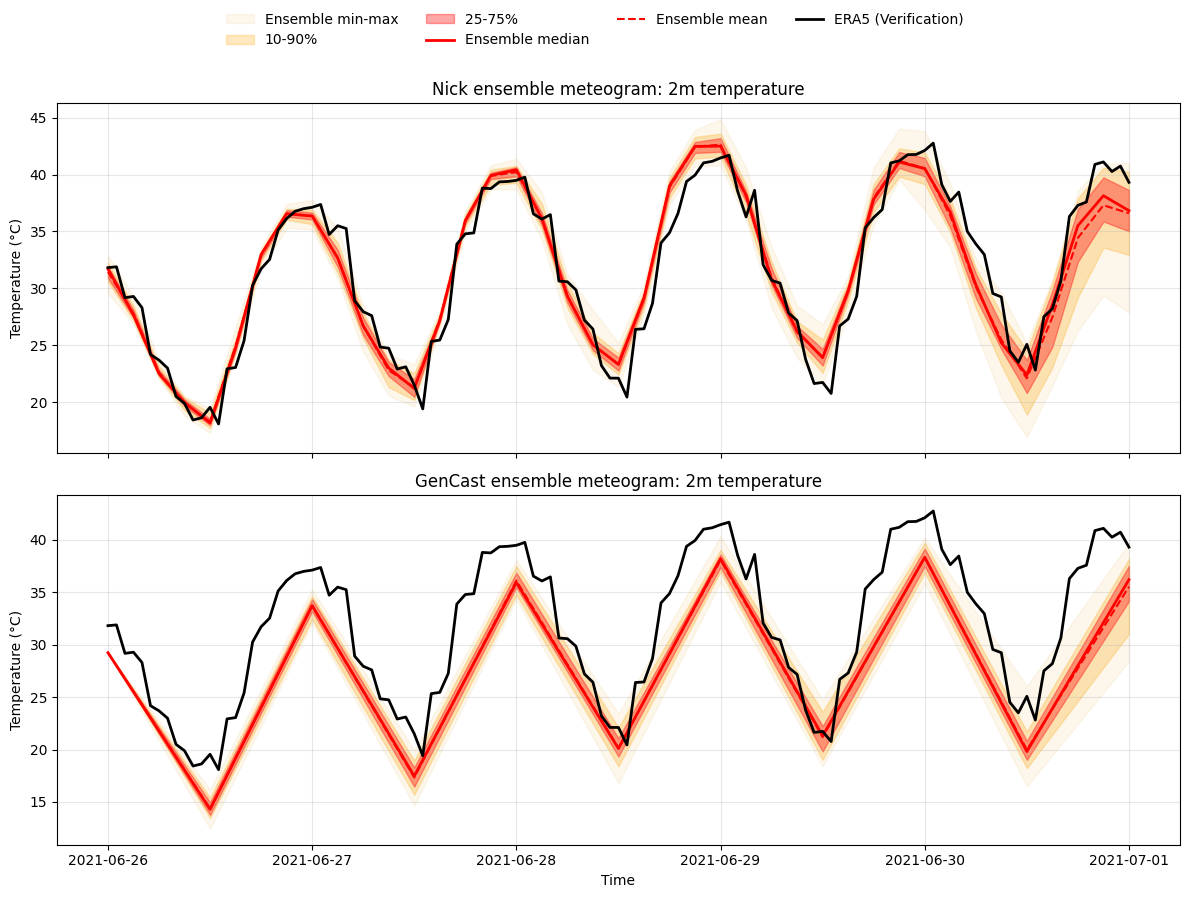

In [8]:
# meteogram-style plot showing ensemble distribution

era5 = xr.open_dataset("/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/era5/pnw025/sfc/2021.nc", engine="netcdf4")
nick = xr.open_dataset("/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-26.nc", engine="netcdf4")

lead3day_seed_paths = [
    (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-26T00_10d/pred_1deg_current_init-2021-06-26T00_10d_seed0_26ens.zarr"),
    (DATA_ROOT + "/gencast/predictions/1deg/current/init-2021-06-26T00_10d/pred_1deg_current_init-2021-06-26T00_10d_seed1_24ens.zarr"),
]
gencast = combine_seed_ensembles(lead3day_seed_paths)
#gencast_path = f"predictions/init_{gencast_init_date}T00_30d_8ens_predictions.zarr"

if "batch" in gencast.dims:
    gencast = gencast.squeeze("batch")

era5 = standardize(era5)
nick = standardize(nick)
gencast = standardize(gencast)

era5_var = "t2m"
nick_var = "t2m"
gencast_var = "2m_temperature"

# Restrict ERA5 to forecast period
era5 = era5.sel(time=slice("2021-06-26T00:00:00", "2021-07-01T12:00:00"))

era5_da = maybe_to_celsius(era5[era5_var])
nick_da = maybe_to_celsius(nick[nick_var])
gencast_da = maybe_to_celsius(gencast[gencast_var])


# --------------------------------------------------
# 6. Spatial max over region
# --------------------------------------------------
def spatial_max(da, latmin, latmax, lonmin, lonmax):
    latmin = float(latmin)
    latmax = float(latmax)
    lonmin = float(lonmin)
    lonmax = float(lonmax)

    # Handle 0-360 longitude datasets (GenCast)
    if float(da.longitude.max()) > 180:
        lonmin = lonmin % 360
        lonmax = lonmax % 360

    # Latitude slice direction
    if da.latitude.values[0] < da.latitude.values[-1]:
        lat_slice = slice(latmin, latmax)
    else:
        lat_slice = slice(latmax, latmin)

    # Longitude slice direction
    if da.longitude.values[0] < da.longitude.values[-1]:
        lon_slice = slice(lonmin, lonmax)
    else:
        lon_slice = slice(lonmax, lonmin)

    subset = da.sel(latitude=lat_slice, longitude=lon_slice)
    print("subset sizes:", subset.sizes)

    return subset.max(dim=("latitude", "longitude"))


# Region bounds
latmin = 50.2-1#30#nick_da.latitude.min()
latmax = 50.2+1#70#nick_da.latitude.max()
longmin = -121.6-1#-150#nick_da.longitude.min()
longmax = -121.6+1#-100#nick_da.longitude.max()

era5_ts = spatial_max(era5_da, latmin, latmax, longmin, longmax)
nick_ts = spatial_max(nick_da, latmin, latmax, longmin, longmax)
gencast_ts = spatial_max(gencast_da, latmin, latmax, longmin, longmax)

if "batch" in gencast_ts.dims:
    gencast_ts = gencast_ts.squeeze("batch")

if np.issubdtype(gencast_ts.time.dtype, np.timedelta64):
    base_time = pd.to_datetime(era5_da.time.values[0])
    absolute_times = base_time + gencast_ts.time #+np.timedelta64(12, "h")
    gencast_ts = gencast_ts.assign_coords(time=absolute_times)


# --------------------------------------------------
# 9. Align common time range
# --------------------------------------------------
common_start = max(
    era5_ts.time.values[0],
    nick_ts.time.values[0],
    #gencast_ts.time.values[0],
)
common_end = min(
    era5_ts.time.values[-1],
    nick_ts.time.values[-1],
    #gencast_ts.time.values[-1],
)

era5_ts = era5_ts.sel(time=slice(common_start, common_end))
nick_ts = nick_ts.sel(time=slice(common_start, common_end))
gencast_ts = gencast_ts.sel(time=slice(common_start, common_end))

# --------------------------------------------------
# 10. Ensemble summary
# --------------------------------------------------
def ensemble_summary(da, ens_dim="number"):
    da = da.squeeze()

    if ens_dim not in da.dims:
        return {
            "median": da,
            "mean": da,
            "min": da,
            "max": da,
            "p10": da,
            "p25": da,
            "p75": da,
            "p90": da,
            "control": None,
        }

    summary = {
        "median": da.quantile(0.50, dim=ens_dim),
        "mean": da.mean(dim=ens_dim),
        "min": da.min(dim=ens_dim),
        "max": da.max(dim=ens_dim),
        "p10": da.quantile(0.10, dim=ens_dim),
        "p25": da.quantile(0.25, dim=ens_dim),
        "p75": da.quantile(0.75, dim=ens_dim),
        "p90": da.quantile(0.90, dim=ens_dim),
        "control": da.sel({ens_dim: 0}) if 0 in da[ens_dim] else None,
    }
    return summary

nick_sum = ensemble_summary(nick_ts, ens_dim="number")
gencast_sum = ensemble_summary(gencast_ts, ens_dim="number" if "number" in gencast_ts.dims else None)


# --------------------------------------------------
# 11. Plot function
# --------------------------------------------------
def plot_meteogram(ax, summary, truth=None, control_ts=None, title="", ylabel="Temperature (°C)"):
    t = summary["median"].time

    ax.fill_between(
        t, summary["min"].values, summary["max"].values,
        alpha=0.25, label="Ensemble min-max", color="wheat"
    )
    ax.fill_between(
        t, summary["p10"].values, summary["p90"].values,
        alpha=0.25, label="10-90%", color="orange"
    )
    ax.fill_between(
        t, summary["p25"].values, summary["p75"].values,
        alpha=0.35, label="25-75%", color="red"
    )

    ax.plot(
        t, summary["median"].values,
        linewidth=2.0, label="Ensemble median", color="red"
    )
    ax.plot(
        t, summary["mean"].values,
        linewidth=1.5, linestyle="--", label="Ensemble mean", color="red"
    )

    if control_ts is not None:
        ax.plot(
            control_ts.time, control_ts.values,
            linewidth=1.2, linestyle=":", label="ERA5 init data", color="tab:blue"
        )

    if truth is not None:
        ax.plot(
            truth.time, truth.values,
            linewidth=2.0, label="ERA5 (Verification)", color="black"
        )

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

plot_meteogram(
    axes[0],
    nick_sum,
    truth=era5_ts,
    title="Nick ensemble meteogram: 2m temperature"
)

plot_meteogram(
    axes[1],
    gencast_sum,
    truth=era5_ts,
    title="GenCast ensemble meteogram: 2m temperature"
)

axes[-1].set_xlabel("Time")

handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

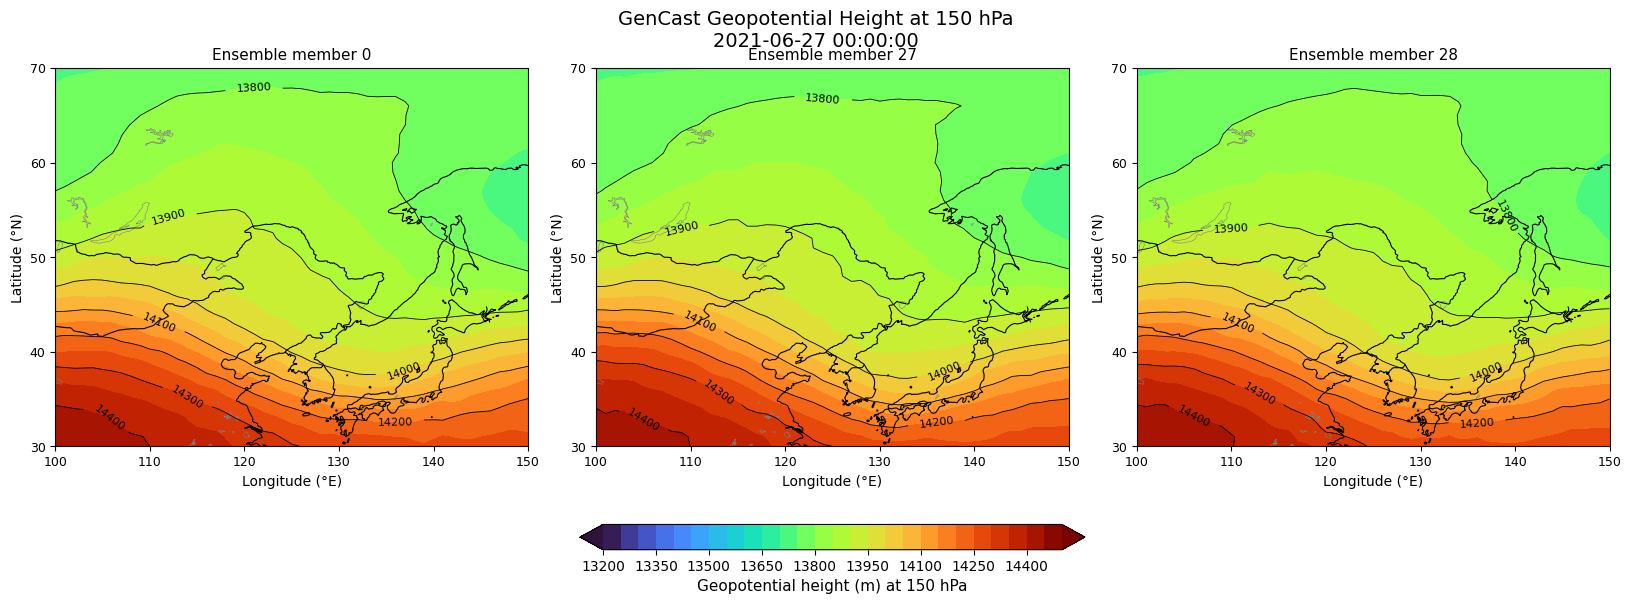

In [29]:
target_time = pd.Timestamp("2021-06-27T00:00:00")
level_hpa = 150
members_to_plot = [0, 27, 28]   # change as needed

lat_min, lat_max = 30, 70
lon_min, lon_max = 100, 150

# Make a fresh copy of GenCast and standardize it
gencast_geo = gencast.copy()
gencast_geo = standardize(gencast_geo)

if "batch" in gencast_geo.dims and gencast_geo.sizes["batch"] == 1:
    gencast_geo = gencast_geo.squeeze("batch")

# Anchor lead-time coordinates to absolute time using ERA5 as the base
if np.issubdtype(gencast_geo["time"].dtype, np.timedelta64):
    base_time = pd.to_datetime(era5_da.time.values[0])
    gencast_geo = gencast_geo.assign_coords(time=base_time + gencast_geo["time"])

def select_region(da, lat_min, lat_max, lon_min, lon_max):
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"

    lon_vals = da[lon_name].values
    if float(np.nanmax(lon_vals)) > 180:
        lon_min = lon_min % 360
        lon_max = lon_max % 360

    if da[lat_name].values[0] < da[lat_name].values[-1]:
        lat_slice = slice(lat_min, lat_max)
    else:
        lat_slice = slice(lat_max, lat_min)

    if lon_vals[0] < lon_vals[-1]:
        lon_slice = slice(lon_min, lon_max)
    else:
        lon_slice = slice(lon_max, lon_min)

    return da.sel({lat_name: lat_slice, lon_name: lon_slice})

def geopotential_height_150(gencast_ds, target_time, member, level_hpa=150):
    z = gencast_ds["geopotential"].sel(time=target_time, level=level_hpa, method="nearest")

    if "number" not in z.dims:
        raise ValueError("No ensemble dimension 'number' found in geopotential.")

    if member < 0 or member >= z.sizes["number"]:
        raise IndexError(f"member={member} is out of range for number size={z.sizes['number']}")

    # Geopotential [m^2/s^2] -> geopotential height [m]
    return z.isel(number=member) / 9.80665

member_fields = {}
for m in members_to_plot:
    gh = geopotential_height_150(gencast_geo, target_time, m, level_hpa=level_hpa)
    gh = select_region(gh, lat_min, lat_max, lon_min, lon_max)
    member_fields[m] = gh

ncols = len(members_to_plot)
fig, axes = plt.subplots(
    1, ncols,
    figsize=(5.4 * ncols, 5.8),
    subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True
)

if ncols == 1:
    axes = [axes]

# --------------------------------------------------
# Manual colour scale
# --------------------------------------------------
vmin = 13200
vmax = 14500
step = 50

levels = np.arange(vmin, vmax + step, step)

for ax, m in zip(axes, members_to_plot):
    hgt = member_fields[m]

    cf = ax.contourf(
        hgt.longitude, hgt.latitude, hgt,
        levels=levels, cmap="turbo", extend="both",
        transform=ccrs.PlateCarree()
    )

    cs = ax.contour(
        hgt.longitude, hgt.latitude, hgt,
        levels=levels[::2], colors="k", linewidths=0.6,
        transform=ccrs.PlateCarree()
    )
    ax.clabel(cs, inline=True, fontsize=8, fmt="%.0f")

    ax.coastlines(resolution="50m", linewidth=0.8)
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.8)
    ax.add_feature(cfeature.LAKES.with_scale("50m"), edgecolor="gray", facecolor="none", linewidth=0.4)

    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax.set_xticks(np.arange(lon_min, lon_max + 1, 10), crs=ccrs.PlateCarree())
    ax.set_yticks(np.arange(lat_min, lat_max + 1, 10), crs=ccrs.PlateCarree())
    ax.tick_params(labelsize=9)

    ax.set_title(f"Ensemble member {m}", fontsize=11)
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")

cbar = fig.colorbar(cf, ax=axes, orientation="horizontal", pad=0.08, fraction=0.06)
cbar.set_label(f"Geopotential height (m) at {level_hpa} hPa", fontsize=11)

fig.suptitle(
    f"GenCast Geopotential Height at {level_hpa} hPa\n{target_time:%Y-%m-%d %H:%M:%S}",
    fontsize=14, y=1.02
)

plt.show()

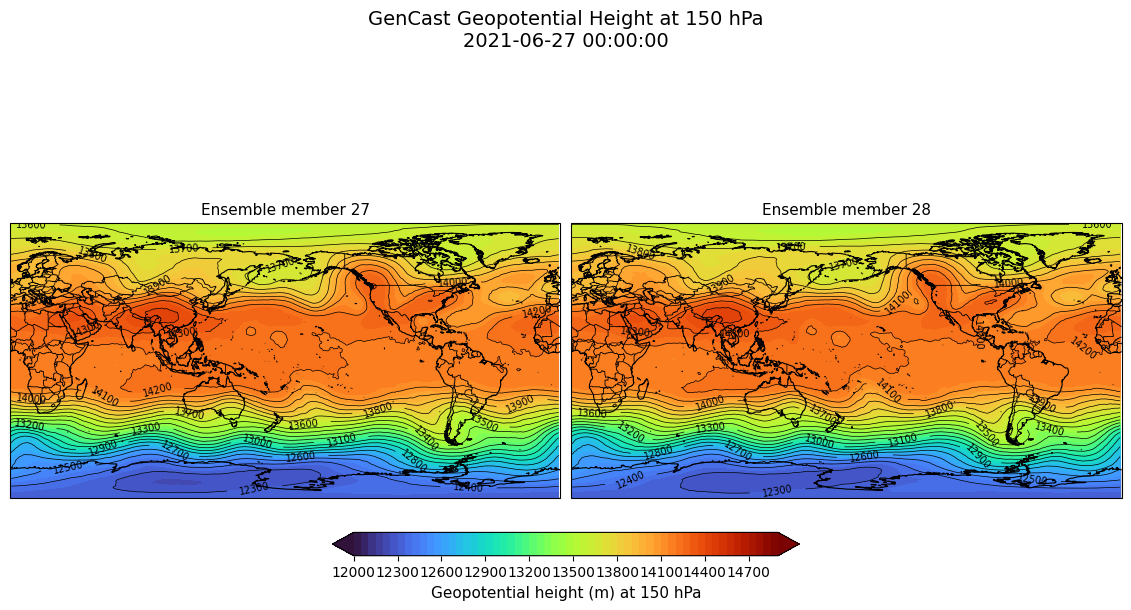

In [ ]:
# User inputs
target_time = pd.Timestamp("2021-06-27T00:00:00")
level_hpa = 150

# Choose the ensemble members you want to plot
members_to_plot = [27, 28]

# ----------------------------
# Prepare GenCast
# ----------------------------
gencast_geo = gencast.copy()
gencast_geo = standardize(gencast_geo)

if "batch" in gencast_geo.dims and gencast_geo.sizes["batch"] == 1:
    gencast_geo = gencast_geo.squeeze("batch")

# Anchor forecast lead times to absolute time if needed
if np.issubdtype(gencast_geo["time"].dtype, np.timedelta64):
    base_time = pd.to_datetime(era5_da.time.values[0])
    gencast_geo = gencast_geo.assign_coords(time=base_time + gencast_geo["time"])

# ----------------------------
# Helper: geopotential height for one member
# ----------------------------
def geopotential_height_150(gencast_ds, target_time, member, level_hpa=150):
    """
    Return geopotential height (m) for one ensemble member at one time and one pressure level.
    GenCast geopotential is assumed to be in m^2/s^2, so divide by g.
    """
    z = gencast_ds["geopotential"].sel(time=target_time, level=level_hpa, method="nearest")

    if "number" not in z.dims:
        raise ValueError("No ensemble dimension 'number' found in geopotential.")

    if member < 0 or member >= z.sizes["number"]:
        raise IndexError(f"member={member} is out of range for number size={z.sizes['number']}")

    z_member = z.isel(number=member)
    return z_member / 9.80665

# ----------------------------
# Build fields for selected members
# ----------------------------
member_fields = {}
for m in members_to_plot:
    gh = geopotential_height_150(gencast_geo, target_time, m, level_hpa=level_hpa)
    member_fields[m] = gh

# ----------------------------
# Plot
# ----------------------------
ncols = len(members_to_plot)
fig, axes = plt.subplots(
    1, ncols,
    figsize=(5.6 * ncols, 5.8),
    subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)},
    constrained_layout=True
)

if ncols == 1:
    axes = [axes]

# --------------------------------------------------
# Manual colour scale
# --------------------------------------------------
vmin = 12000
vmax = 14900
step = 50

levels = np.arange(vmin, vmax + step, step)

for ax, m in zip(axes, members_to_plot):
    hgt = member_fields[m]

    # Ensure longitude is sorted for smooth global contouring
    if "longitude" in hgt.coords:
        hgt = hgt.sortby("longitude")

    cf = ax.contourf(
        hgt.longitude, hgt.latitude, hgt,
        levels=levels, cmap="turbo", extend="both",
        transform=ccrs.PlateCarree()
    )

    cs = ax.contour(
        hgt.longitude, hgt.latitude, hgt,
        levels=levels[::2], colors="k", linewidths=0.5,
        transform=ccrs.PlateCarree()
    )
    ax.clabel(cs, inline=True, fontsize=7, fmt="%.0f")

    ax.set_global()
    ax.coastlines(resolution="50m", linewidth=0.8)
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.6)
    ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="none", edgecolor="gray", linewidth=0.2)
    ax.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor="none")

    ax.set_title(f"Ensemble member {m}", fontsize=11)

cbar = fig.colorbar(cf, ax=axes, orientation="horizontal", pad=0.07, fraction=0.05)
cbar.set_label(f"Geopotential height (m) at {level_hpa} hPa", fontsize=11)

fig.suptitle(
    f"GenCast Geopotential Height at {level_hpa} hPa\n{target_time:%Y-%m-%d %H:%M:%S}",
    fontsize=14, y=1.03
)

plt.show()